# Analyse de données sur le syndrome des ovaires polykystiques (SOPK)

# Choix du dataset

J'ai choisi ce dataset sur Kaggle car le syndrome des ovaires polykystiques touche de nombreuses femmes et reste sous-diagnostiqué. En démontrant des corrélations statistiques, nous pouvons rechercher plus tôt le SOPK (PCOS en anglais) et ainsi éviter les retards de prise en charge.

In [ ]:
# Import des librairies

import os # Operating system pour accéder au fichier csv
import pandas as pd # Panel data pour faire la primo-analyse de données
import matplotlib.pyplot as plt # Matplotlib pour créer des graphiques
import seaborn as sns # Seaborn pour créer des graphiques
import numpy as np # Numpy pour l'analyse
from scipy.stats import spearmanr # Scipy pour l'analyse (matrice de corrélation)
from scipy.stats import mannwhitneyu # Scipy pour l'analyse (test non paramétrique de Mann-Whitney)

In [ ]:
# Import des données depuis Kagglehub et téléchargement de la dernière version
import kagglehub
path = kagglehub.dataset_download("samikshadalvi/pcos-diagnosis-dataset")
print("Path to dataset files:", path)

# Assignation du fichier csv à une variable et chargement du fichier CSV dans un dataframe
path="/root/.cache/kagglehub/datasets/samikshadalvi/pcos-diagnosis-dataset/versions/1"
file_name = "pcos_dataset.csv"
full_path = os.path.join(path, file_name) # concaténation de path et file_name
print(full_path)
df = pd.read_csv(full_path)

Using Colab cache for faster access to the 'pcos-diagnosis-dataset' dataset.
Path to dataset files: /kaggle/input/pcos-diagnosis-dataset
/root/.cache/kagglehub/datasets/samikshadalvi/pcos-diagnosis-dataset/versions/1/pcos_dataset.csv


# Informations générales sur le fichier

In [ ]:
# Informations sur les données du fichier : catégories, nombre d'individus par catégorie, type de données
info = df.info()
display (info)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Age                        1000 non-null   int64  
 1   BMI                        1000 non-null   float64
 2   Menstrual_Irregularity     1000 non-null   int64  
 3   Testosterone_Level(ng/dL)  1000 non-null   float64
 4   Antral_Follicle_Count      1000 non-null   int64  
 5   PCOS_Diagnosis             1000 non-null   int64  
dtypes: float64(2), int64(4)
memory usage: 47.0 KB


None

Selon ces informations, aucune valeur n'est manquante sur les mille patientes incluses dans l'étude.

La colonne Dtype rapporte un type sur toute la colonne qui est consistant sur, donc il n'y a pas besoin de nettoyer les données car il n'y a pas de parasite.

In [ ]:
# Aperçu des cinq premières lignes du fichier
head = df.head()
display (head)

,Age,BMI,Menstrual_Irregularity,Testosterone_Level(ng/dL),Antral_Follicle_Count,PCOS_Diagnosis
0,24,34.7,1,25.2,20,0
1,37,26.4,0,57.1,25,0
2,32,23.6,0,92.7,28,0
3,28,28.8,0,63.1,26,0
4,25,22.1,1,59.8,8,0


# Primo-analyse

In [ ]:
# Par catégorie : nombre de patientes, moyenne, déviation standard (étalement des valeurs autour de la moyenne), minimum, quartiles, maximum
df.describe()

,Age,BMI,Menstrual_Irregularity,Testosterone_Level(ng/dL),Antral_Follicle_Count,PCOS_Diagnosis
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,31.771000,26.38700,0.530000,60.159500,17.469000,0.199000
std,8.463462,4.93554,0.499349,23.160204,7.069301,0.399448
min,18.000000,18.10000,0.000000,20.000000,5.000000,0.000000
25%,24.000000,21.90000,0.000000,41.700000,12.000000,0.000000
50%,32.000000,26.40000,1.000000,60.000000,18.000000,0.000000
75%,39.000000,30.50000,1.000000,80.300000,23.250000,0.000000
max,45.000000,35.00000,1.000000,99.800000,29.000000,1.000000


In [ ]:
# Distribution du diagnostic de SOPK et proportion de femmes diagnostiquées
print("Distribution du diagnostic SOPK :")
print(df["PCOS_Diagnosis"].value_counts())
print(f"Proportion de SOPK positifs : {df['PCOS_Diagnosis'].mean():.2%}")

Distribution du diagnostic SOPK :
PCOS_Diagnosis
0    801
1    199
Name: count, dtype: int64
Proportion de SOPK positifs : 19.90%


Il y a 19,90% de femmes qui ont été diagnostiquées atteintes du SOPK dans l'échantillon.

Nous allons réaliser des boîtes à moustaches des variables quantitatives, qui sont l'âge, l'IMC, le taux de testostérone et le nombre de follicules antraux. Nous ne le faisons pas pour l'irrégularité menstruelle qui est une variable qualitative (on a un indicateur qui vaut 0 si on ne l'a pas et 1 si on l'a).

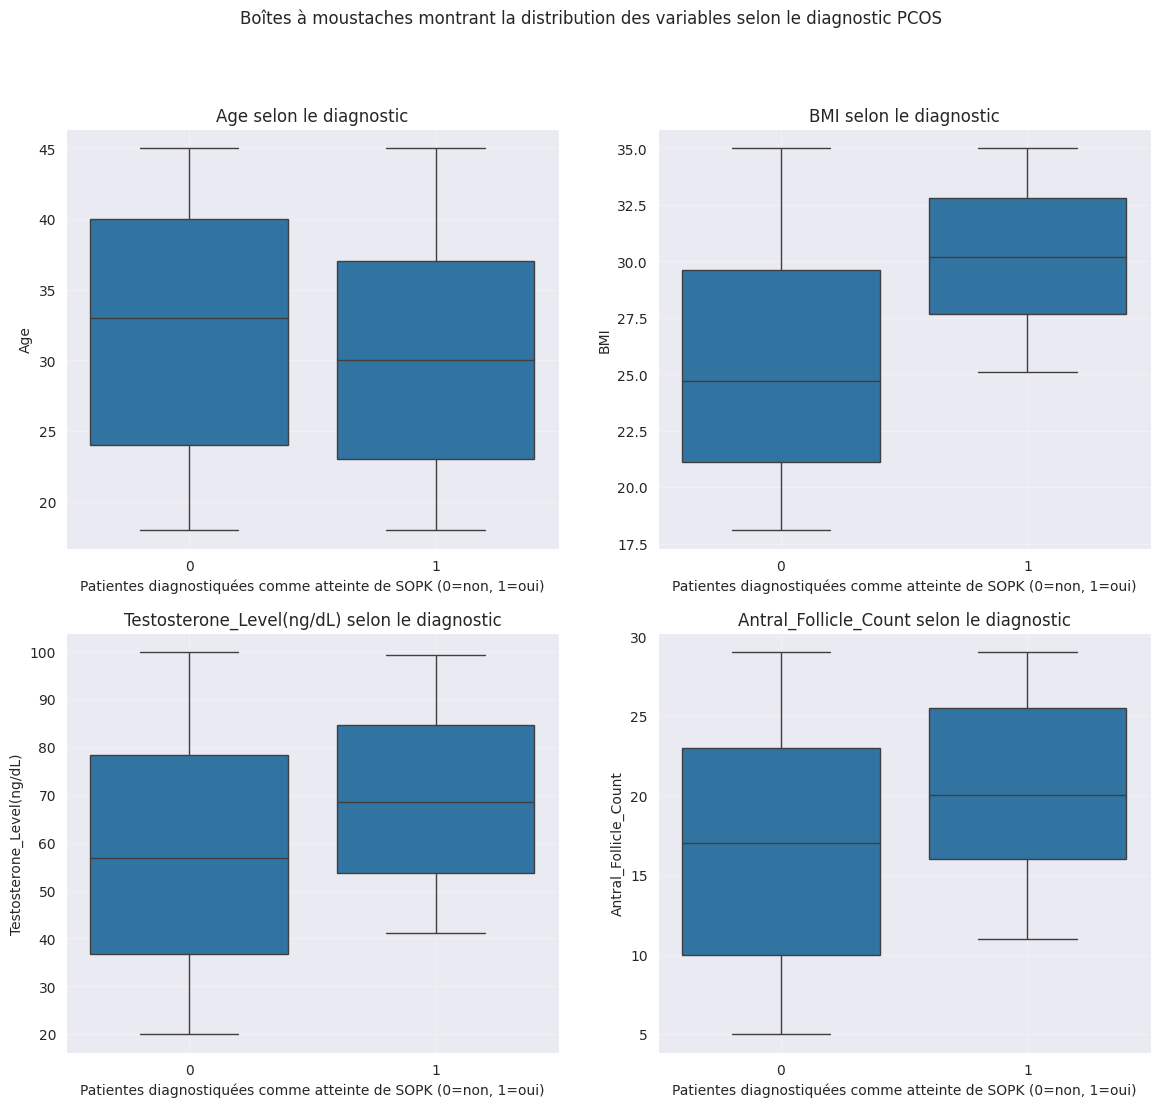

In [ ]:
# Boîtes à moustaches des variables quantitatives

# Grille de graphiques
sns.set_style("darkgrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("Boîtes à moustaches montrant la distribution des variables selon le diagnostic PCOS")

# Variables quantitatives à analyser
var_quant = ["Age", "BMI", "Testosterone_Level(ng/dL)", "Antral_Follicle_Count"]

# Pour chaque variable quantitative , création d'un boxplot comparant patientes diagnostiquées du SOPK et patientes non diagnostiquées du SOPK
for idx, var in enumerate(var_quant): # afin de situer sur quel boxplot nous sommes, nous utilisons idx qui va de 0 à 3. Chaque position de boxplot est détermminée par un couple (0;0),(0;1),(1;0),(1;1)
    row = idx // 2 # ici, row prendra respectivement comme valeurs : 0;0;1;1 pour idx qui vaut 0;1;2;3
    col = idx % 2 # ici, col prendra respectivement comme valeurs : 0;1;0;1 pour idx qui vaut 0;1;2;3. Ainsi, on reconstitue les couples
    sns.boxplot(data=df, x="PCOS_Diagnosis", y=var, ax=axes[row, col])
    axes[row, col].set_title(f"{var} selon le diagnostic")
    axes[row, col].set_xlabel("Patientes diagnostiquées comme atteinte de SOPK (0=non, 1=oui)")
    axes[row, col].grid(True, alpha=0.3)
plt.show()

Au vu de ces boîtes à moustaches, il semblerait qu'il y ait une distribution similaire de l'âge, peu importe le diagnostic ou non.

De plus, l'écart de médiane entre patientes diagnostiquées et non diagnostiquées laisse à penser qu'il y a une significativité statistique pour l'IMC.

On voit également un effet de seuil pour le taux de testostérone et le nombre de follicules antraux car on remarque que les minima sont éloignés entre les patientes diagnostiquées et non diagnostiquées.

# Matrice de corrélation de Spearman

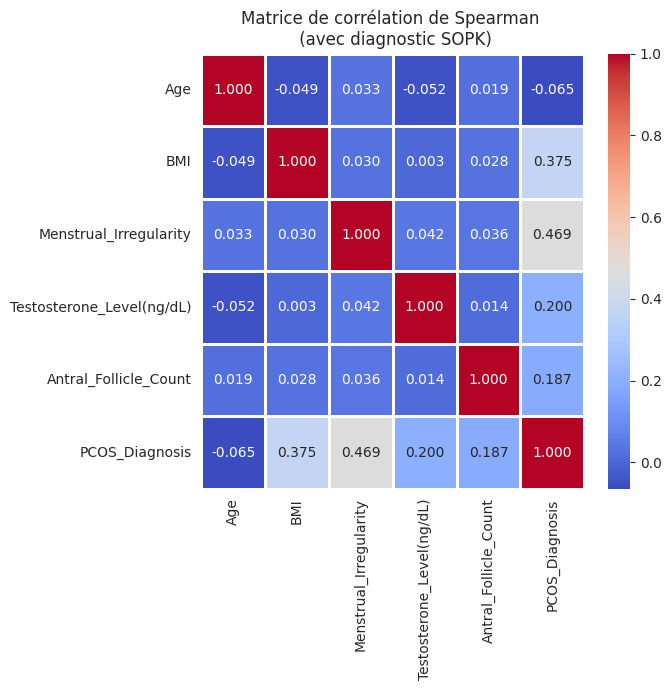

In [ ]:
# Matrice de corrélation de Spearman incluant le diagnostic SOPK
var_PCOS = ["Age", "BMI", "Menstrual_Irregularity", "Testosterone_Level(ng/dL)", "Antral_Follicle_Count", "PCOS_Diagnosis"]

matrice_complete = df[var_PCOS].corr(method="spearman")

plt.figure(figsize=(7, 7))
sns.heatmap(matrice_complete, annot=True, cmap="coolwarm", fmt=".3f",linewidths=1)
plt.title("Matrice de corrélation de Spearman \n (avec diagnostic SOPK)")
plt.tight_layout()
plt.show()

La matrice de corrélation de Spearman montre la force de la corrélation de l'IMC, de l'irrégularité menstruelle, du taux de testostérone et du nombre de follicules antraux, avec le diagnostic de SOPK. Nous pouvons remarquer que l'âge et le diagnostic de SOPK ne sont pas corrélés, ce qui signifie qu'il n'y a pas de lien statistique entre ces deux données, alors que l'irrégularité menstruelle est fortement corrélée.

Maintenant, analysons séparément le lien, avec le diagnostic du SOPK, du nombre de follicules antraux, du taux de testostérone, de l'IMC et de l'irrégularité menstruelle (du moins au plus corrélé au diagnostic de SOPK).

# Analyse du nombre moyen de follicules antraux

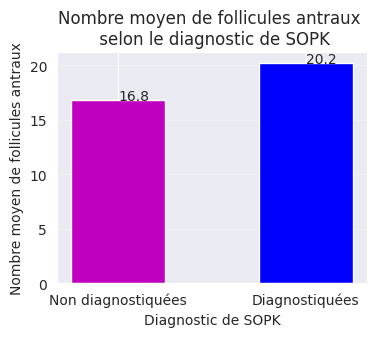

In [ ]:
# Diagramme en barre du nombre de follicules antraux selon le diagnostic de SOPK

# Variables contenant la moyenne du nombre de follicules antraux des patientes diagnostiquées ou non du SOPK
mean_PCOS_follicles = df[df["PCOS_Diagnosis"]==1]["Antral_Follicle_Count"].mean()
mean_nonPCOS_follicles = df[df["PCOS_Diagnosis"]==0]["Antral_Follicle_Count"].mean()

# Création du diagramme en barre
fig, ax = plt.subplots(figsize=(4, 3))
x = [0, 0.2] # position des deux barres
width = 0.1 # largeur de chaque barre
bars = ax.bar(x, [mean_nonPCOS_follicles, mean_PCOS_follicles], width, color=["m", "b"]) # attribution de la variable contenant la moyenne à chaque barre
for bar in bars: # pour chaque barre, la boucle récupère la hauteur de la barre et écrit la valeur en haut avec 1 chiffre après la virgule
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height, f"{height:.1f}")
ax.set_xlabel("Diagnostic de SOPK")
ax.set_ylabel("Nombre moyen de follicules antraux")
ax.set_title("Nombre moyen de follicules antraux \n selon le diagnostic de SOPK")
ax.set_xticks(x)
ax.set_xticklabels(["Non diagnostiquées", "Diagnostiquées"])
ax.grid(axis="y", alpha=0.3)
plt.show()

Nous constatons un écart entre le nombre de follicules antraux chez les patientes non diagnostiquées et celui des patientes diagnostiquées atteintes de SOPK. Montrons-le par un test de significativité, et pour cela regardons si le nombre de follicules suit une loi de distribution particulière.

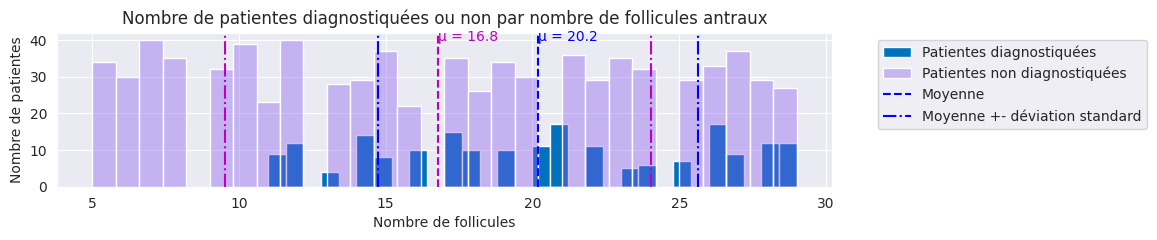

In [ ]:
# Histogramme du nombre de patientes atteintes de SOPK ou non en fonction du nombre de follicules antraux

# Variables contenant le nombre de follicules antraux des patientes diagnostiquées ou non du SOPK, et écarts-types
PCOS_follicles = df[df["PCOS_Diagnosis"]==1]["Antral_Follicle_Count"]
nonPCOS_follicles = df[df["PCOS_Diagnosis"]==0]["Antral_Follicle_Count"]
std_PCOS_follicles=PCOS_follicles.std()
std_nonPCOS_follicles=nonPCOS_follicles.std()

# Création de l'histogramme
fig, ax = plt.subplots(figsize=(10,2))
ax.hist(PCOS_follicles, 30, color="#0072BD", label="Patientes diagnostiquées") # nombre de patientes diagnostiquées en fonction du nombre de follicules
ax.hist(nonPCOS_follicles, 30, color="#8756F060", label="Patientes non diagnostiquées") # nombre de patientes non diagnostiquées en fonction du nombre de follicules
ax.set_title("Nombre de patientes diagnostiquées ou non par nombre de follicules antraux")
ax.set_xlabel("Nombre de follicules")
ax.set_ylabel("Nombre de patientes")
ax.axvline(mean_PCOS_follicles, color="b", linestyle="--", label="Moyenne") # moyenne du nombre de follicules pour les patientes diagnostiquées
ax.axvline(mean_PCOS_follicles+std_PCOS_follicles, color="b", linestyle="-.", label="Moyenne +- déviation standard") # moyenne+écart-type pour les patientes diagnostiquées
ax.axvline(mean_PCOS_follicles-std_PCOS_follicles, color="b", linestyle="-.") # moyenne-écart-type pour les patientes diagnostiquées
ax.axvline(mean_nonPCOS_follicles, color="m", linestyle="--") # moyenne du nombre de follicules pour les patientes non diagnostiquées
ax.axvline(mean_nonPCOS_follicles+std_nonPCOS_follicles, color="m", linestyle="-.") # moyenne-écart+type pour les patientes non diagnostiquées
ax.axvline(mean_nonPCOS_follicles-std_nonPCOS_follicles, color="m", linestyle="-.") # moyenne-écart-type pour les patientes non diagnostiquées
y_max = ax.get_ylim()[1] # stocke la hauteur maximale, pour écrire la valeur de la moyenne en haut grâce à y_max*0.95 soit 95% de la hauteur totale
ax.text(mean_PCOS_follicles, y_max*0.95, f"μ = {mean_PCOS_follicles:.1f}", color="b")
ax.text(mean_nonPCOS_follicles, y_max*0.95, f"μ = {mean_nonPCOS_follicles:.1f}", color="m")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # légende à côté du graphique sinon c'est illisible
plt.show()

Le nombre de follicules antraux ne montre pas de suivi de loi de distribution particulière, nous allons donc utiliser le test de Mann-Whitney (test non paramétrique) pour voir si les écarts de moyenne entre patientes diagnostiquées et non diagnostiquées est significatif.

In [ ]:
# Test de Mann-Whitney

stat, p_value = mannwhitneyu(PCOS_follicles, nonPCOS_follicles, alternative='two-sided') # test bilatéral, compare deux groupes indépendants

print(f"Statistique du test : {stat:.2f}") # mesure du chevauchement des deux groupes, s'il s'éloigne de 0 les groupes sont séparés
print(f"P-value : {p_value:.4e}") # donne la significativité de la différence

if p_value < 0.05:
    print("La différence est statistiquement significative (p < 0.05)")
else:
    print("La différence n'est pas significative (p ≥ 0.05)")

Statistique du test : 101286.50
P-value : 3.1229e-09
La différence est statistiquement significative (p < 0.05)


Ainsi, la différence entre les moyennes du nombre de follicules antraux chez les femmes diagnostiquées du SOPK et chez celles qui ne le sont pas, est significative.

# Graphique du taux de testostérone en fonction de l'IMC

Essayons de voir si la testostérone a une distribution particulière :

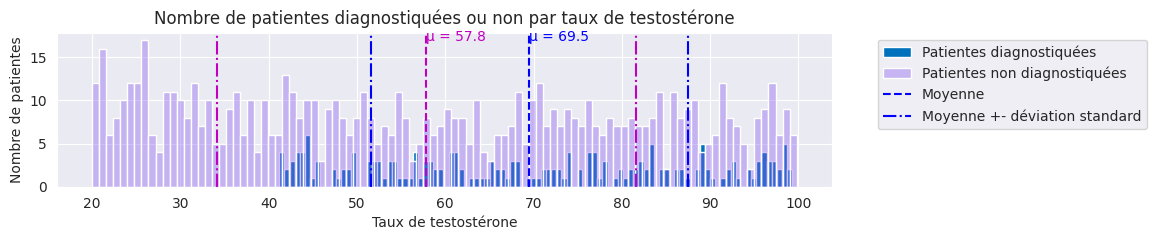

In [ ]:
# Histogramme du nombre de patientes atteintes de SOPK ou non en fonction du taux de testostérone

# Variables contenant les taux de testostérone des patientes diagnostiquées ou non du SOPK, moyennes et écarts-types
PCOS_testo = df[df["PCOS_Diagnosis"]==1]["Testosterone_Level(ng/dL)"]
nonPCOS_testo = df[df["PCOS_Diagnosis"]==0]["Testosterone_Level(ng/dL)"]
mean_PCOS_testo,std_PCOS_testo=PCOS_testo.mean(),PCOS_testo.std()
mean_nonPCOS_testo,std_nonPCOS_testo=nonPCOS_testo.mean(),nonPCOS_testo.std()

# Création de l'histogramme
fig, ax = plt.subplots(figsize=(10,2))
ax.hist(PCOS_testo, 100, color="#0072BD", label="Patientes diagnostiquées") # nombre de patientes diagnostiquées en fonction du taux de testostérone
ax.hist(nonPCOS_testo, 100, color="#8756F060", label="Patientes non diagnostiquées") # nombre de patientes non diagnostiquées en fonction du taux de testostérone
ax.set_title("Nombre de patientes diagnostiquées ou non par taux de testostérone")
ax.set_xlabel("Taux de testostérone")
ax.set_ylabel("Nombre de patientes")
ax.axvline(mean_PCOS_testo, color="b", linestyle="--", label="Moyenne") # moyenne du taux de testostérone pour les patientes diagnostiquées
ax.axvline(mean_PCOS_testo+std_PCOS_testo, color="b", linestyle="-.", label="Moyenne +- déviation standard") # moyenne+écart-type pour les patientes diagnostiquées
ax.axvline(mean_PCOS_testo-std_PCOS_testo, color="b", linestyle="-.") # moyenne-écart-type pour les patientes diagnostiquées
ax.axvline(mean_nonPCOS_testo, color="m", linestyle="--") # moyenne du taux de testostérone pour les patientes non diagnostiquées
ax.axvline(mean_nonPCOS_testo+std_nonPCOS_testo, color="m", linestyle="-.") # moyenne+écart-type pour les patientes non diagnostiquées
ax.axvline(mean_nonPCOS_testo-std_nonPCOS_testo, color="m", linestyle="-.") # moyenne-écart-type pour les patientes non diagnostiquées
y_max = ax.get_ylim()[1] # stocke la hauteur maximale, pour écrire la valeur de la moyenne en haut grâce à y_max*0.95 soit 95% de la hauteur totale
ax.text(mean_PCOS_testo, y_max*0.95, f"μ = {mean_PCOS_testo:.1f}", color="b")
ax.text(mean_nonPCOS_testo, y_max*0.95, f"μ = {mean_nonPCOS_testo:.1f}", color="m")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # légende à côté du graphique sinon c'est illisible
plt.show()

Il semblerait que le taux de testostérone n'ait pas de distribution particulière. Nous observons un effet de seuil, avec une valeur minimum qui est plus élevée dans la population diagnostiquée que dans la population non diagnostiquée. Les écarts-types montrent que l'écart à la moyenne est moindre chez les patientes diagnostiquées du SOPK, on a donc des données moins étalées.

Voyons pour l'IMC.

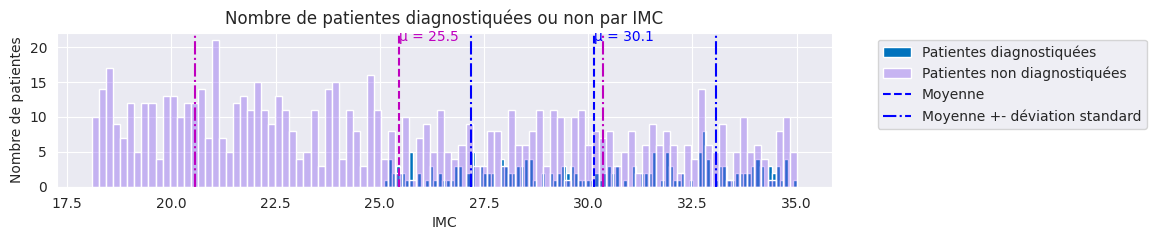

In [ ]:
# Histogramme du nombre de patientes atteintes de SOPK ou non en fonction de l'IMC

# Variables contenant les taux de testostérone des patientes diagnostiquées ou non de l'IMC, moyennes et écarts-types
PCOS_BMI = df[df["PCOS_Diagnosis"]==1]["BMI"]
nonPCOS_BMI = df[df["PCOS_Diagnosis"]==0]["BMI"]
mean_PCOS_BMI,std_PCOS_BMI=PCOS_BMI.mean(),PCOS_BMI.std()
mean_nonPCOS_BMI,std_nonPCOS_BMI=nonPCOS_BMI.mean(),nonPCOS_BMI.std()

# Création de l'histogramme
fig, ax = plt.subplots(figsize=(10,2))
ax.hist(PCOS_BMI, 100, color="#0072BD", label="Patientes diagnostiquées") # nombre de patientes diagnostiquées en fonction de l'IMC
ax.hist(nonPCOS_BMI, 100, color="#8756F060", label="Patientes non diagnostiquées") # nombre de patientes non diagnostiquées en fonction de l'IMC
ax.set_title("Nombre de patientes diagnostiquées ou non par IMC")
ax.set_xlabel("IMC")
ax.set_ylabel("Nombre de patientes")
ax.axvline(mean_PCOS_BMI, color="b", linestyle="--", label="Moyenne") # moyenne de l'IMC pour les patientes diagnostiquées
ax.axvline(mean_PCOS_BMI+std_PCOS_BMI, color="b", linestyle="-.", label="Moyenne +- déviation standard") # moyenne+écart-type pour les patientes diagnostiquées
ax.axvline(mean_PCOS_BMI-std_PCOS_BMI, color="b", linestyle="-.") # moyenne-écart-type pour les patientes diagnostiquées
ax.axvline(mean_nonPCOS_BMI, color="m", linestyle="--") # moyenne de l'IMC pour les patientes non diagnostiquées
ax.axvline(mean_nonPCOS_BMI+std_nonPCOS_BMI, color="m", linestyle="-.") # moyenne+écart-type pour les patientes non diagnostiquées
ax.axvline(mean_nonPCOS_BMI-std_nonPCOS_BMI, color="m", linestyle="-.") # moyenne-écart-type pour les patientes non diagnostiquées
y_max = ax.get_ylim()[1] # stocke la hauteur maximale, pour écrire la valeur de la moyenne en haut grâce à y_max*0.95 soit 95% de la hauteur totale
ax.text(mean_PCOS_BMI, y_max*0.95, f"μ = {mean_PCOS_BMI:.1f}", color="b")
ax.text(mean_nonPCOS_BMI, y_max*0.95, f"μ = {mean_nonPCOS_BMI:.1f}", color="m")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # légende à côté du graphique sinon c'est illisible
plt.show()

Il semblerait que l'IMC n'ait pas non plus de distribution particulière.  Nous observons un effet de seuil, avec une valeur minimum qui est plus élevée dans la population diagnostiquée que dans la population non diagnostiquée. Les écarts-types montrent que l'écart à la moyenne est moindre chez les patientes diagnostiquées du SOPK, on a donc des données moins étalées.

Croisons la testostérone et l'IMC, et comparons les personnes diagnostiquées et personnes non diagnostiquées.

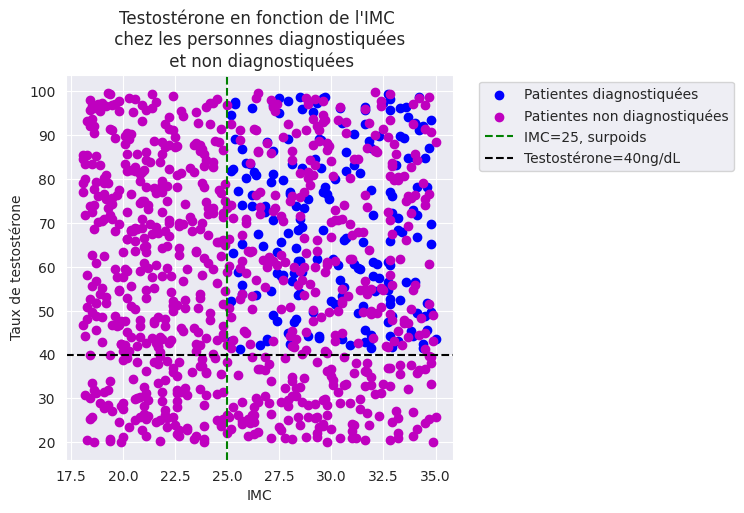

In [ ]:
# Nuage de points de la testostérone en fonction de l'IMC

# Variables contenant l'IMC et variables contenant la testostérone chez les patientes diagnostiquées et non diagnostiquées
PCOS_bmi = df[df["PCOS_Diagnosis"]==1]["BMI"]
PCOS_testo = df[df["PCOS_Diagnosis"]==1]["Testosterone_Level(ng/dL)"]
nonPCOS_bmi = df[df["PCOS_Diagnosis"]==0]["BMI"]
nonPCOS_testo = df[df["PCOS_Diagnosis"]==0]["Testosterone_Level(ng/dL)"]

# Création du nuage de points
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(PCOS_bmi, PCOS_testo, c="b", label="Patientes diagnostiquées") # patientes diagnostiquées, avec leur IMC en abscisse et leur taux de testostérone en ordonnée
ax.scatter(nonPCOS_bmi, nonPCOS_testo, c="m",label="Patientes non diagnostiquées") # patientes non diagnostiquées, avec leur IMC en abscisse et leur taux de testostérone en ordonnée
ax.set_title("Testostérone en fonction de l'IMC \n chez les personnes diagnostiquées \n et non diagnostiquées")
ax.set_xlabel("IMC")
ax.set_ylabel("Taux de testostérone")
ax.axvline(25.0, color="g", linestyle="--", label="IMC=25, surpoids") # limite du surpoids, axe vertical car c'est le seuil IMC=25
ax.axhline(40, color="k", linestyle="--", label="Testostérone=40ng/dL") # seuil de testostérone=40ng/dL, axe horizontal car c'est de la testostérone
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # légende à côté du graphique sinon c'est illisible
plt.show()

Le graphique montre que l'IMC des personnes non diagnostiquées est très variable, en revanche chez toutes les personnes diagnostiquées de l'échantillon, il est supérieur ou égal à 25. On retrouve donc un effet de seuil.
Ainsi, un IMC important est un symptôme qui peut faire rechercher un SOPK.

Le graphique montre également que le taux de testostérone des personnes diagnostiquées du SOPK est compris entre 40 et 100, alors que ce taux est compris entre 20 et 100 chez la population des patientes non diagnostiquées. On retrouve donc un effet de seuil.
Ainsi, un taux de testostérone important est un symptôme qui peut faire rechercher un SOPK.

L'IMC et le taux de testostérone sont les variables quantitatives les plus corrélées au diagnostic, selon la matrice de corrélation de Spearman. Néanmoins, la matrice de corrélation nous montre que l'IMC et le taux de testostérone ne sont pas corrélés entre eux (sans prise en compte du diagnostic).

# Analyse de l'irrégularité menstruelle

L'irrégularité menstruelle est une donnée qualitative qui ne peut prendre que 0 ou 1 comme valeur pour chaque patiente, elle suit une loi binomiale. Estimons la probabilité p de succès et l'espérance.

In [ ]:
# Sélection de la colonne irrégularité menstruelle et transformation du dataframe en tableau à une variable numpy
irreg = df["Menstrual_Irregularity"].to_numpy()

total_irreg = len(irreg) # nombre de personnes dans l'échantillon qui ont une valeur d'irrégularité menstruelle (0=non, 1=oui), soit 1000 patientes
succes_irreg = irreg.sum() # nombre de personnes qui présentent une irrégularité menstruelle

p_irreg = succes_irreg / total_irreg # proportion de patientes au cycle irrégulier sur l'ensemble des patientes
print(f"La probabilité p vaut {p_irreg} donc {p_irreg*100}% des patientes présentent une irrégularité menstruelle dans l'échantillon.")

esperance = 1000 * p_irreg # espérance binomiale E = n*p
print(f"L'espérance E vaut {esperance} donc sur {total_irreg}, on s'attend à avoir {esperance:.0f} patientes au cycle irrégulier.") # j'ai mis .0f car sinon on a un nombre décimal, or on ne peut pas avoir de patiente partielle

La probabilité p vaut 0.53 donc 53.0% des patientes présentent une irrégularité menstruelle dans l'échantillon.
L'espérance E vaut 530.0 donc sur 1000, on s'attend à avoir 530 patientes au cycle irrégulier.


Comparons à présent l'irrégularité menstruelle chez les personnes atteintes de SOPK et celles qui ne sont pas diagnostiquées.

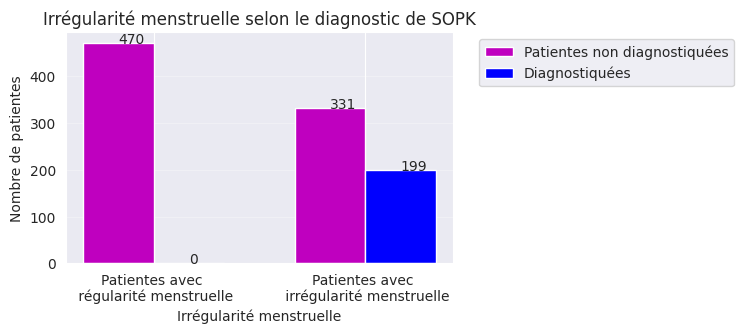

In [ ]:
# Diagramme en barre de l'irrégularité menstruelle selon le diagnostic de SOPK

# Variables contenant l'information irrégularité menstruelle des patientes diagnostiquées ou non du SOPK
PCOS_irreg = df[df["PCOS_Diagnosis"]==1]["Menstrual_Irregularity"]
nonPCOS_irreg = df[df["PCOS_Diagnosis"]==0]["Menstrual_Irregularity"]

# Comptage des valeurs
PCOS_regular = (PCOS_irreg == 0).sum()
PCOS_irregular = (PCOS_irreg == 1).sum()
nonPCOS_regular = (nonPCOS_irreg == 0).sum()
nonPCOS_irregular = (nonPCOS_irreg == 1).sum()

# Création du diagramme en barre
fig, ax = plt.subplots(figsize=(5, 3))
x = np.array([0, 0.3]) # position des deux barres
width = 0.1 # largeur de chaque barre
bars1 = ax.bar(x - width/2, [nonPCOS_regular, nonPCOS_irregular], width, label="Patientes non diagnostiquées", color="m") # barre pour le nombre de patientes non diagnostiquées, d'une part sans irrégularité, d'autre part avec irrégularité menstruelle
bars2 = ax.bar(x + width/2, [PCOS_regular, PCOS_irregular], width, label="Diagnostiquées", color="b") # barre pour le nombre de patientes diagnostiquées, d'une part sans irrégularité, d'autre part avec irrégularité menstruelle
for bars in [bars1, bars2]: # pour chaque barre, la boucle récupère la hauteur de la barre et écrit la valeur en haut
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height, f'{int(height)}')
ax.set_xlabel("Irrégularité menstruelle")
ax.set_ylabel("Nombre de patientes")
ax.set_title("Irrégularité menstruelle selon le diagnostic de SOPK")
ax.set_xticks(x)
ax.set_xticklabels(["Patientes avec \n régularité menstruelle", "Patientes avec \n irrégularité menstruelle"])
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # légende à côté du graphique sinon c'est illisible
ax.grid(axis="y", alpha=0.3)
plt.show()

Ce graphique montre que toutes les patientes atteintes de SOPK présentent une irrégularité menstruelle dans cet échantillon. Toutefois, des patientes au cycle menstruel irrégulier ne sont pas diagnostiquées, donc il ne s'agit pas d'un symptôme certain, mais il peut permettre d'orienter précocement une patiente vers un diagnostic de SOPK.

# Limites

L'échantillon de l'étude comporte 1000 patientes, ce qui induit un biais de représentativité.

En outre, l'étude sur Kaggle ne précise pas comment ces patientes ont été sélectionnées. Sachant que la distribution des valeurs ne suit pas de loi de distribution particulière, on peut supposer qu'il ne s'agit pas de données générées artificiellement. Cependant, au vu du fait que l'absence d'irrégularité menstruelle assure de façon certaine d'être avec une patiente non diagnostiquée du SOPK, nous suspectons un biais de sélection.

De plus, il faudrait s'assurer que les données ont été établies sans biais d'opérateur. Pour l'irrégularité menstruelle, comme on a 0 ou 1 (régularité ou irrégularité), il n'y a pas de gradient donc il serait intéressant que ces données soient confirmées par un autre opérateur. Sinon, nous pourrions envisager de transformer cette donnée qualitative en une donnée quantitative, en la substituant par exemple par le nombre de cycles qu'une femme a par an.
Enfin, il faudrait prendre en compte les cas d'aménorrhée et les cas de régularité liée par un apport hormonal externe (pilule, stérilet hormonal, patch).

# Conclusion

Le diagnostic du SOPK est corrélé à l'irrégularité menstruelle, au taux de testostérone, à un IMC supérieur à 25 et à la quantité de follicules antraux. La détection de ces symptômes peut orienter le praticien vers une recherche de SOPK afin de permettre un diagnostic et une prise en charge plus précoces.

Mathilde Théry